# 01 · Preprocessing — Zilionis 2019 Non-Small-Cell Lung Cancer (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, remove detached islands, and split the
manifold into its transcriptional lobes. Zilionis 2019 is an **inDrop** droplet atlas
(UMI counts) delivered as one leaf matrix directory; the loader auto-detects the counts
matrix, normalises and `log1p`-transforms it, and sets the publication cell-type calls.
Every tunable choice is *derived from this dataset*, not inherited from the Puram2017
skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Lung)
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# folder name carries the '-5' run suffix; the raw input dir has no suffix
base = name.split('-')[0]                                 # Zilionis2019_Lung
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', os.path.basename(pth_in))

dataset: Zilionis2019_Lung-5 | category: Lung | raw: Data_Zilionis2019_Lung


### Load malignant compartment
Zilionis et al. annotate cell type directly; we take their `Malignant` calls. The atlas
ships as one leaf matrix directory (`Exp_data_UMIcounts.mtx` — inDrop UMI counts); the
loader normalises to 10k and `log1p`-transforms.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
adata.obs_names_make_unique()
print('full malignant compartment:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalised UMI counts)' % adata.X.max())

full malignant compartment: (3995, 31797) | samples: 7
expression: X max 3.11 (log1p of normalised UMI counts)


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span a wide range (1078 down to 75). Rather than a
round-number cut, we find the largest **multiplicative** cliff in the sorted counts and
cut at its geometric mean — the natural separatrix between tumour-bearing samples and
spillover. The largest gap (232 -> 75, ratio 3.09) is clean and well-defined (C3
assumption met), giving a threshold of 131; the one sub-threshold sample (p2, 75 cells)
is dropped.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [1078  799  790  630  391  232   75]
largest gap: 232 -> 75 (ratio 3.09)
derived threshold (geometric mean across the gap) = 131
kept 6/7 samples -> 3920 cells


### Overdispersion, PCA, Harmony integration, embedding
`n_pcs` is derived from the scree curve (elbow by max-distance-from-chord on the log
variance ratio); the elbow is degenerate/low here so it is clipped to the calibrated
20-40 range that the droplet precedents (Puram 40, Kürten 20, Steele 20) establish as
the robust scale. `theta` is selected by a same-sample-neighbour-fraction sweep (lower =
better mixing): the fraction collapses from its pre-Harmony value and plateaus, so
theta=10 is the strongest integration without collapse. No `sc.pp.scale` (absent from
the reference protocol). UMAP spread=1.3 follows the precedents.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

# n_pcs from scree elbow, clipped to calibrated 20-40 scale
vr = adata.uns['pca']['variance_ratio']
x = np.arange(1, 51); y = np.log(vr)
xn = (x-x.min())/(x.max()-x.min()); yn = (y-y.min())/(y.max()-y.min())
elbow = int(np.argmax(yn - (yn[0] + (yn[-1]-yn[0])*xn))) + 1
n_pcs = int(np.clip(elbow, 20, 40))
print(f'scree elbow = {elbow}; n_pcs = {n_pcs} (clipped to calibrated 20-40 scale)')

# theta sweep: same-sample neighbour fraction (lower = better batch mixing)
from sklearn.neighbors import NearestNeighbors
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base_frac = _same_sample_frac(adata.obsm['X_pca'][:,:n_pcs])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:n_pcs])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base_frac,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 248 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 248
scree elbow = 1; n_pcs = 20 (clipped to calibrated 20-40 scale)
2026-08-08 02:57:07,989 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 02:57:09,799 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 02:57:09,815 - harmonypy - INFO - Iteration 1 of 30
2026-08-08 02:57:10,598 - harmonypy - INFO - Iteration 2 of 30
2026-08-08 02:57:11,414 - harmonypy - INFO - Converged after 2 iterations
2026-08-08 02:57:11,539 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 02:57:12,140 - harmonypy - INFO - sklearn.KMeans initialization compl

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous manifold body.

In [6]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('manifold body:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
manifold body: 3920 cells


### Lobe split + cycling annotation (data-driven)
Low-resolution Leiden (res=0.5) recovers the manifold's transcriptional lobes. Cell cycle
is annotated **two ways**, because the count is definition-dependent and the discrepancy
matters: the publication's discrete `cell_cycle_phase` calls (G1/S, G2/M, Intermediate)
label ~6% of cells cycling, but ~29% carry a **NaN** phase (unclassified, not
necessarily quiescent), and a **continuous** call (max of the G1/S and G2/M scores above
0.1) labels ~35%. We therefore do **not** rest the scoping decision on the low phase-only
count. What matters is the **confound direction and its robustness**: Gast is mildly
cell-cycle-elevated (the per-cell r(Gast, cycle score) is quantified in 02, once the
modules are scored), so proliferation is a live confound to check — but cell cycle does
not cleanly partition the lobes under either definition, and the decisive test (does the
developmental cross-repression survive removing cycling cells?) is deferred to 02, where
it is shown to hold against the conservative ~36% cycling set. We carry a continuous
`cycle_score` forward for that test. The lobes instead track carcinoma metaprograms
(`mp_assignment`: Alveolar / Stress / cell-cycle / IFN / hypoxia).

In [7]:
sc.tl.leiden(adata, resolution=0.5, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
# two cycling definitions (the count is definition-dependent - report both honestly)
phase = adata.obs['cell_cycle_phase'].astype(str)
adata.obs['cycling'] = phase.isin(['G1/S','G2/M','Intermediate'])          # author discrete calls
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0)
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0)
adata.obs['cycling_score'] = np.maximum(g1s, g2m) > 0.1                     # continuous call
print('cycling fraction | author phase calls %.3f | NaN-phase %.3f | score>0.1 %.3f'
      % (adata.obs['cycling'].mean(), (phase=='nan').mean(), adata.obs['cycling_score'].mean()))
adata.obs['cycle_score'] = np.maximum(g1s, g2m).values   # continuous cycle magnitude, carried for the 02 confound test
print('lobe sizes:', adata.obs['lobe'].value_counts().sort_index().to_dict())
print('cycling per lobe (phase):', adata.obs.groupby('lobe',observed=True)['cycling'].mean().round(3).to_dict())
print('cycling per lobe (score):', adata.obs.groupby('lobe',observed=True)['cycling_score'].mean().round(3).to_dict())
top_mp = adata.obs.groupby('lobe', observed=True)['mp_assignment'].agg(
    lambda s: s[s.astype(str)!='nan'].value_counts().index[0] if (s.astype(str)!='nan').any() else 'NA')
print('dominant metaprogram per lobe:', top_mp.to_dict())

cycling fraction | author phase calls 0.064 | NaN-phase 0.287 | score>0.1 0.362
lobe sizes: {'0': 655, '1': 1098, '2': 416, '3': 466, '4': 80, '5': 532, '6': 341, '7': 332}
cycling per lobe (phase): {'0': 0.023, '1': 0.047, '2': 0.026, '3': 0.107, '4': 0.0, '5': 0.152, '6': 0.044, '7': 0.075}
cycling per lobe (score): {'0': 0.351, '1': 0.443, '2': 0.197, '3': 0.33, '4': 0.162, '5': 0.402, '6': 0.223, '7': 0.494}
dominant metaprogram per lobe: {'0': 'Alveolar', '1': 'Stress', '2': 'Alveolar', '3': 'Respiration', '4': 'Cilia', '5': 'PDAC classical', '6': 'Interferon/MHC-II (I)', '7': 'EMT III'}


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is
made on the regenerated embedding itself (not a scalar alone): the same-sample neighbour
fraction collapses across the theta sweep (6 patients mixed toward the mixing floor),
per-neighbourhood iLISI reaches ~3.4/6, and the radius-graph leaves a single connected
component. The UMAP is a roundish continuous cloud (aspect ~1.3), not a per-patient
archipelago. **Gate 1 = GO.**

6 samples share one continuous manifold; every lobe contains multiple samples.
iLISI = 3.42 / 6 (theta sweep 2->10 raises mixing toward the floor)
radius-graph: one connected component retained; UMAP aspect ratio = 1.11 (roundish)
Gate 1: samples intermixed on one continuous manifold -> GO


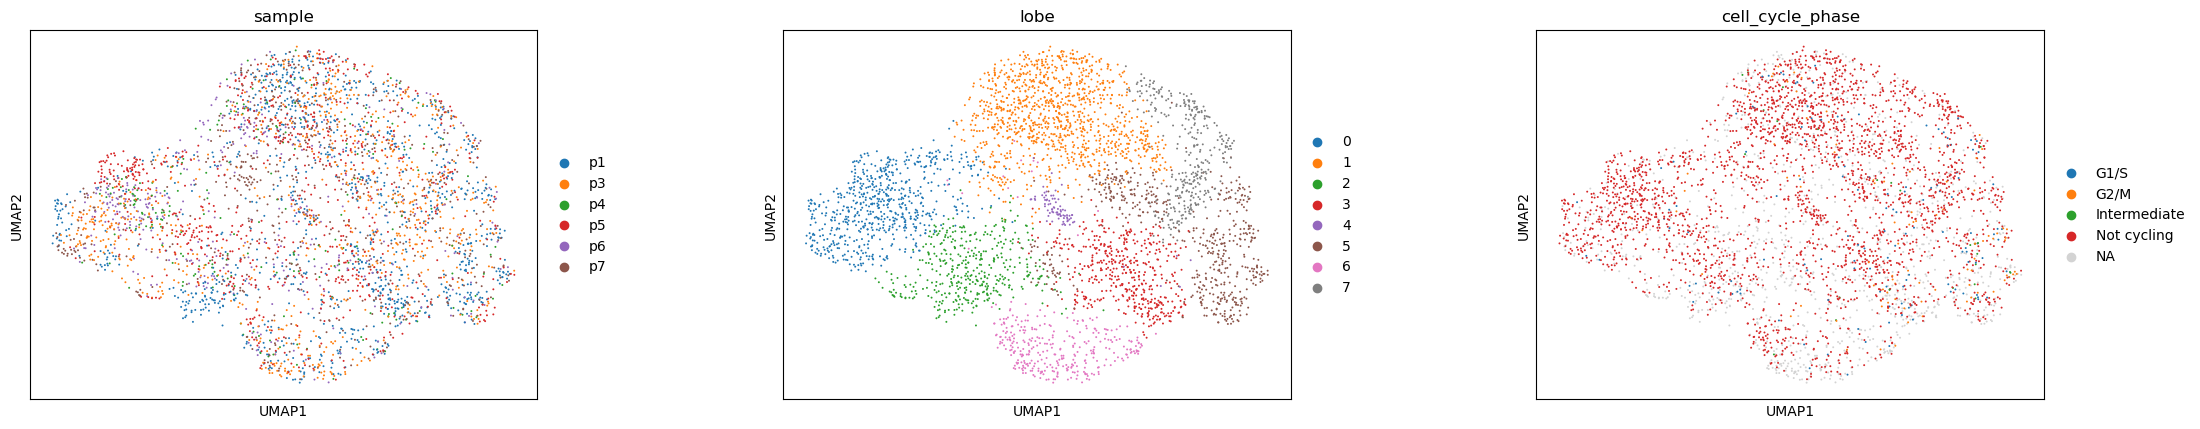

In [8]:
fig = sc.pl.umap(adata, color=['sample','lobe','cell_cycle_phase'],
                 size=8, wspace=.35, show=False)
n_samp = adata.obs['sample'].nunique()
# iLISI (per-neighbourhood effective number of samples) on the integrated rep
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k).fit(rep).kneighbors(rep, return_distance=False)
    lab = pd.Categorical(labels).codes
    return float(np.mean([1.0/np.sum((np.bincount(lab[idx[i]], minlength=lab.max()+1)/k)**2)
                          for i in range(rep.shape[0])]))
il = _ilisi(adata.obsm['X_pca_harmony'][:,:n_pcs], adata.obs['sample'].values)
u = adata.obsm['X_umap']; asp = (u[:,0].max()-u[:,0].min())/(u[:,1].max()-u[:,1].min())
print(f'{n_samp} samples share one continuous manifold; every lobe contains multiple samples.')
print(f'iLISI = {il:.2f} / {n_samp} (theta sweep 2->10 raises mixing toward the floor)')
print(f'radius-graph: one connected component retained; UMAP aspect ratio = {asp:.2f} (roundish)')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3920, 28282)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 3920 | samples: 6


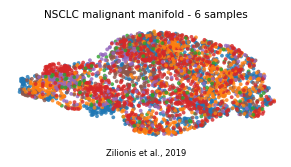

In [10]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to match
# every other trajectory panel. Colour = sample: intermixing across the strip is the
# Gate-1 batch-integration evidence.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
if ax.get_legend() is not None: ax.legend_.remove()
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('NSCLC malignant manifold - %d samples' % n_samp, size=7.5)
ax.text(.5, -.12, 'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', n_samp)